#Kütüphanelerin Kurulumu

In [1]:
!pip install transformers torch datasets pandas

In [2]:
!pip install -U torch torchvision torchaudio transformers datasets scikit-learn pandas

#Veriyi Kod İçine Çekme ve DataFrame'e Çevirme

In [3]:
import pandas as pd
from datasets import load_dataset

# Hugging Face üzerinden ürün yorumları veri setini doğrudan indiriyoruz
dataset = load_dataset("fthbrmnby/turkish_product_reviews")

# İşlemesi ve tablolaması kolay olsun diye Pandas DataFrame'e çeviriyoruz
df = dataset['train'].to_pandas()

# Veri setindeki sütun isimleri: 'sentence' (Yorum) ve 'sentiment' (0: Negatif, 1: Pozitif)
# Verinin ilk 5 satırını ekrana yazdırıp kontrol edelim:
print("Veri Setinden İlk 5 Satır:")
print(df.head())

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Veri Setinden İlk 5 Satır:
                                            sentence  sentiment
0                        fena değil paraya göre iyi.          1
1  ürün kaliteli ve çok kullanışlı kargo ya veril...          1
2  fiyat-performans karşılaştırması yaptığınızda ...          1
3                                  bu fiyata çok iyi          1
4               fiyat ve performans olarak gayet iyi          1


#EDA

In [4]:
import pandas as pd
import re

print("--- 1. TEMİZLİK ÖNCESİ VERİ DURUMU ---")
print(f"Toplam Satır Sayısı: {len(df)}")
print(f"Boş (Null) Değer Sayısı:\n{df.isnull().sum()}\n")
print(f"Tekrarlayan (Kopya) Satır Sayısı: {df.duplicated(subset=['sentence']).sum()}\n")

# --- 2. VERİ TEMİZLEME İŞLEMLERİ ---

# A. Boş (Null) değerleri siliyoruz
df.dropna(subset=['sentence', 'sentiment'], inplace=True)

# B. Kopya (Mükerrer) satırları siliyoruz
df.drop_duplicates(subset=['sentence'], inplace=True)

# C. İçindeki çöp karakterleri (HTML, Linkler vb.) temizleyen fonksiyon
def metin_temizle(metin):
    if not isinstance(metin, str):
        return metin
    # HTML etiketlerini temizle (Örn: <br>, <div>)
    metin = re.sub(r'<.*?>', ' ', metin)
    # URL'leri ve linkleri temizle
    metin = re.sub(r'http\S+|www\S+|https\S+', '', metin, flags=re.MULTILINE)
    # Fazladan boşlukları teke düşür ve baş/sondaki boşlukları at
    metin = re.sub(r'\s+', ' ', metin).strip()
    return metin

# Temizleme fonksiyonunu tüm yorumlara uygulayıp 'clean_sentence' adında yeni sütun açıyoruz
df['clean_sentence'] = df['sentence'].apply(metin_temizle)

print("--- 3. TEMİZLİK SONRASI VERİ DURUMU ---")
print(f"Kalan Temiz Satır Sayısı: {len(df)}")
print("Örnek Temizlenmiş Veri:")
print(df[['sentence', 'clean_sentence']].head(3))

--- 1. TEMİZLİK ÖNCESİ VERİ DURUMU ---
Toplam Satır Sayısı: 235165
Boş (Null) Değer Sayısı:
sentence     0
sentiment    0
dtype: int64

Tekrarlayan (Kopya) Satır Sayısı: 1657

--- 3. TEMİZLİK SONRASI VERİ DURUMU ---
Kalan Temiz Satır Sayısı: 233508
Örnek Temizlenmiş Veri:
                                            sentence  \
0                        fena değil paraya göre iyi.   
1  ürün kaliteli ve çok kullanışlı kargo ya veril...   
2  fiyat-performans karşılaştırması yaptığınızda ...   

                                      clean_sentence  
0                        fena değil paraya göre iyi.  
1  ürün kaliteli ve çok kullanışlı kargo ya veril...  
2  fiyat-performans karşılaştırması yaptığınızda ...  


--- Veri Seti Genel Bilgisi ---
<class 'pandas.DataFrame'>
Index: 233508 entries, 0 to 235164
Data columns (total 3 columns):
 #   Column          Non-Null Count   Dtype
---  ------          --------------   -----
 0   sentence        233508 non-null  str  
 1   sentiment       233508 non-null  int64
 2   clean_sentence  233508 non-null  str  
dtypes: int64(1), str(2)
memory usage: 84.4 MB
None

Eksik Değer Sayısı:
 sentence          0
sentiment         0
clean_sentence    0
dtype: int64

--- Sınıf Dağılımı ---
sentiment
1    218747
0     14761
Name: count, dtype: int64


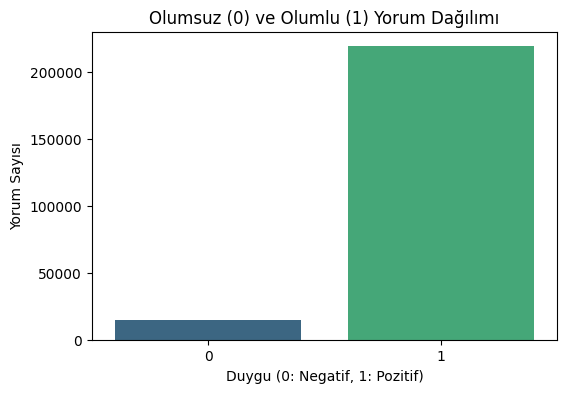


--- Yorum Uzunlukları (Kelime Sayısı) İstatistikleri ---
count    233508.000000
mean         22.321522
std          19.071326
min           0.000000
25%           9.000000
50%          19.000000
75%          28.000000
max         305.000000
Name: word_count, dtype: float64


In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import re

# 1. TEMEL BİLGİLER VE EKSİK VERİ KONTROLÜ
print("--- Veri Seti Genel Bilgisi ---")
print(df.info())
print("\nEksik Değer Sayısı:\n", df.isnull().sum())

# 2. SINIF DAĞILIMI
print("\n--- Sınıf Dağılımı ---")
print(df['sentiment'].value_counts())

# Sınıf dağılımını görselleştirme
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='sentiment', hue='sentiment', legend=False, palette='viridis')
plt.title('Olumsuz (0) ve Olumlu (1) Yorum Dağılımı')
plt.xlabel('Duygu (0: Negatif, 1: Pozitif)')
plt.ylabel('Yorum Sayısı')
plt.show()

# 3. VERİ DÜZENLEME VE TEMİZLİK
# Eksik verileri ve mükerrer (kopya) yorumları siliyoruz
df.dropna(subset=['sentence', 'sentiment'], inplace=True)
df.drop_duplicates(subset=['sentence'], inplace=True)

# İstenmeyen HTML etiketleri ve URL'leri temizleyen basit bir fonksiyon
def metin_temizle(metin):
    if not isinstance(metin, str):
        return metin
    metin = re.sub(r'<.*?>', ' ', metin) # HTML etiketlerini boşlukla değiştir
    metin = re.sub(r'http\S+|www\S+|https\S+', '', metin, flags=re.MULTILINE) # URL'leri sil
    metin = metin.strip() # Başındaki ve sonundaki boşlukları temizle
    return metin

# Temizlik işlemini yeni bir sütuna uyguluyoruz
df['clean_sentence'] = df['sentence'].apply(metin_temizle)

# 4. METİN UZUNLUĞU ANALİZİ
# Temizlenmiş metinlerin kelime sayısını hesaplıyoruz
df['word_count'] = df['clean_sentence'].apply(lambda x: len(str(x).split()))

print("\n--- Yorum Uzunlukları (Kelime Sayısı) İstatistikleri ---")
print(df['word_count'].describe())

#Sınıf Dengesizliği ve Veri Boyutu

In [6]:
# Sınıf dengesini sağlamak için her iki sınıftan 100'er örnek alıyoruz
df_negatif = df[df['sentiment'] == 0].sample(100, random_state=42)
df_pozitif = df[df['sentiment'] == 1].sample(100, random_state=42)

# Bu iki küçük tabloyu birleştirip, model sırasını ezberlemesin diye karıştırıyoruz
test_df = pd.concat([df_negatif, df_pozitif]).sample(frac=1, random_state=42).reset_index(drop=True)

print(f"Test için hazır dengeli veri sayısı: {len(test_df)}")
print("Sınıf Dağılımı:\n", test_df['sentiment'].value_counts())

Test için hazır dengeli veri sayısı: 200
Sınıf Dağılımı:
 sentiment
0    100
1    100
Name: count, dtype: int64


#Pipeline ile Test Etme


In [7]:
from transformers import pipeline

# 3. Doğru Modeli Seçme ve Yükleme
# Belirlediğin Türkçe duygu analizi modelini indiriyoruz
duygu_analizi = pipeline("sentiment-analysis", model="savasy/bert-base-turkish-sentiment-cased")

# 4. Ham Veriyi Modele Gönderme
# Test etmek için veri setimizden rastgele 5 adet yorumu seçip listeye çeviriyoruz
ornek_yorumlar = df['sentence'].sample(5, random_state=42).tolist()

# Listeyi modele veriyoruz ve tahminleri alıyoruz
tahminler = duygu_analizi(ornek_yorumlar)

# 5. Sonuçları Ayrıştırma ve Yorumlama
print("\n--- MODEL TAHMİN SONUÇLARI ---\n")
for metin, sonuc in zip(ornek_yorumlar, tahminler):
    etiket = sonuc['label']
    skor = sonuc['score']

    print(f"Yorum: {metin}")
    print(f"Modelin Tahmini: {etiket} | Güven Skoru: %{skor*100:.2f}")
    print("-" * 50)

config.json:   0%|          | 0.00/596 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/442M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/39.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]


--- MODEL TAHMİN SONUÇLARI ---

Yorum: güzel ve kaliteli, zaten makinesini de hepsiburadan sitesinden almıştım. tebrikler
Modelin Tahmini: positive | Güven Skoru: %94.11
--------------------------------------------------
Yorum: -bir önce ki fakir süpürgemin yanında sesi neredeyse yok gibi.
Modelin Tahmini: negative | Güven Skoru: %99.53
--------------------------------------------------
Yorum: akışı kesik kesik ama koca tenekeyi kaldırmaktansa bu ürün çok kullanışlı bir ürün. gören satın almak istiyor. tavsiye ederim.
Modelin Tahmini: negative | Güven Skoru: %99.87
--------------------------------------------------
Yorum: ürün geldi ama daha kullanmadım bakalım inşallah güzeldir.daha ne yazıyım anlamadım en az 20 kelimeymiş böle saçmalık mı olur benim yorumum 5 kelime belki..
Modelin Tahmini: negative | Güven Skoru: %99.67
--------------------------------------------------
Yorum: telefon fiyatına göre uygun ortalama bir fiyat
Modelin Tahmini: negative | Güven Skoru: %99.52
-----------

#Modeli 200 Satırlık Dengeli Veriye Uygulama

In [16]:
# Tüm temizlenmiş yorumları listeye çevirip modele besliyoruz
print("200 yorum modele gönderiliyor, lütfen bekleyin...")
tüm_tahminler = duygu_analizi(test_df['clean_sentence'].tolist())

# Modelden dönen label ve score değerlerini ayıklıyoruz
tahmin_etiketleri = [sonuc['label'] for sonuc in tüm_tahminler]
guven_skorlari = [sonuc['score'] for sonuc in tüm_tahminler]

# Tablomuza yeni sütunlar olarak ekliyoruz
test_df['model_tahmini_metin'] = tahmin_etiketleri
test_df['guven_skoru'] = guven_skorlari

print("Tahminler başarıyla veri setine eklendi!")

200 yorum modele gönderiliyor, lütfen bekleyin...
Tahminler başarıyla veri setine eklendi!


#Çıktıları Sayısal Formata Çevirme

In [20]:
# Modelin metin çıktılarını 1 ve 0'a dönüştüren bir sözlük (dictionary) haritası
etiket_haritasi = {'positive': 1, 'negative': 0}

# Haritalamayı uygulayıp yeni bir sütun oluşturuyoruz
test_df['model_tahmini_sayi'] = test_df['model_tahmini_metin'].map(etiket_haritasi)

# Gerçek etiket ile tahminin uyuşup uyuşmadığını kontrol eden bir 'Dogru_Bildi_Mi' sütunu ekleyelim
test_df['dogru_bildi_mi'] = test_df['sentiment'] == test_df['model_tahmini_sayi']

# Yanlış bilinen birkaç örneği ekrana yazdırıp "neden yanlış bildiğini" inceleyelim
print("--- MODELİN YANILDIĞI BAZI YORUMLAR ---")
hatali_tahminler = test_df[test_df['dogru_bildi_mi'] == False]
print(hatali_tahminler[['clean_sentence', 'sentiment', 'model_tahmini_sayi']].head())

--- MODELİN YANILDIĞI BAZI YORUMLAR ---
                                       clean_sentence  sentiment  \
5   tostu harika bi şekilde yapıyor lakin balık ko...          1   
8   dizimde varolan sporcu sakatlığı sonucunda çok...          1   
12  logitech kalitesini uygun fiyat ile birleştire...          1   
17  fakat telefon gibi konuşabiliyormuyum? hafıza ...          1   
28               beklediğimden daha kaliteli ve hafif          1   

    model_tahmini_sayi  
5                    0  
8                    0  
12                   0  
17                   0  
28                   0  


#Performans Metrikleri ve Sınıflandırma Raporu (Classification Report)

In [21]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Gerçek değerler ve Modelin tahminleri
gercek_degerler = test_df['sentiment']
tahminler = test_df['model_tahmini_sayi']

# Doğruluk (Accuracy) Skoru
accuracy = accuracy_score(gercek_degerler, tahminler)
print(f"\nModelin Genel Doğruluk Oranı (Accuracy): %{accuracy * 100:.2f}")

# Detaylı Sınıflandırma Raporu
print("\n--- SINIFLANDIRMA RAPORU ---")
print(classification_report(gercek_degerler, tahminler, target_names=['Negatif (0)', 'Pozitif (1)']))


Modelin Genel Doğruluk Oranı (Accuracy): %74.00

--- SINIFLANDIRMA RAPORU ---
              precision    recall  f1-score   support

 Negatif (0)       0.67      0.94      0.78       100
 Pozitif (1)       0.90      0.54      0.68       100

    accuracy                           0.74       200
   macro avg       0.79      0.74      0.73       200
weighted avg       0.79      0.74      0.73       200



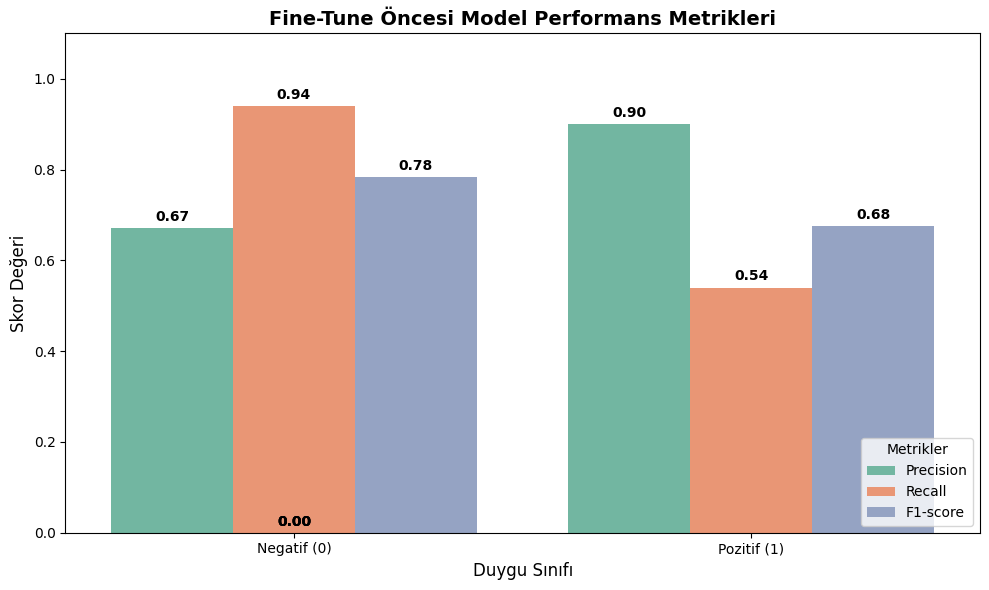

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.metrics import classification_report

# Raporu görselleştirebilmek için arka planda sözlük (dictionary) formatında çekiyoruz
rapor_dict = classification_report(gercek_degerler, tahminler, target_names=['Negatif (0)', 'Pozitif (1)'], output_dict=True)

# Çizdireceğimiz metrikleri ve sınıfları belirliyoruz
metrikler = ['precision', 'recall', 'f1-score']
siniflar = ['Negatif (0)', 'Pozitif (1)']

# Seaborn kütüphanesinin anlayacağı formata (DataFrame) getiriyoruz
grafik_verisi = []
for sinif in siniflar:
    for metrik in metrikler:
        grafik_verisi.append({'Sınıf': sinif, 'Metrik': metrik.capitalize(), 'Değer': rapor_dict[sinif][metrik]})

df_grafik = pd.DataFrame(grafik_verisi)

# --- GRAFİĞİ ÇİZME AŞAMASI ---
plt.figure(figsize=(10, 6))
# Bar plot oluşturma
grafik = sns.barplot(data=df_grafik, x='Sınıf', y='Değer', hue='Metrik', palette='Set2')

# Grafiği makyajlama (İsimler, limitler)
plt.title('Fine-Tune Öncesi Model Performans Metrikleri', fontsize=14, fontweight='bold')
plt.ylim(0, 1.1) # Yüzdeler net görünsün diye tepe noktasını 1.1'e sabitliyoruz
plt.ylabel('Skor Değeri', fontsize=12)
plt.xlabel('Duygu Sınıfı', fontsize=12)

# Barların (sütunların) tam üzerine değerlerini sayısal olarak yazdırma
for p in grafik.patches:
    grafik.annotate(f"{p.get_height():.2f}",
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center',
                    xytext=(0, 8),
                    textcoords='offset points',
                    fontsize=10, fontweight='bold')

# Lejantı (Renk açıklamaları) sağ alta alma
plt.legend(loc='lower right', title='Metrikler')
plt.tight_layout()
plt.show()

/tmp/ipykernel_2497/1919582893.py:14: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(data=test_df, x='sentiment', y='guven_skoru', hue='dogru_bildi_mi',


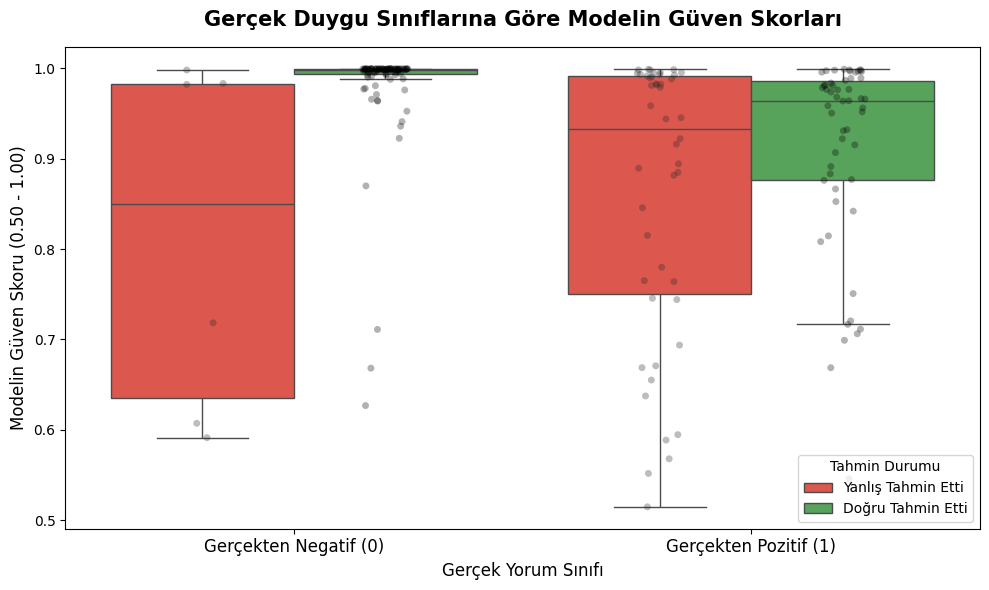

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

# Eğer 'dogru_bildi_mi' sütunun yoksa veya silindiyse diye tekrar oluşturuyoruz
test_df['dogru_bildi_mi'] = test_df['sentiment'] == test_df['model_tahmini_sayi']

plt.figure(figsize=(10, 6))

# Kutu Grafiği (Boxplot) ve üzerine nokta nokta verileri (Stripplot) ekliyoruz
# Böylece hem genel dağılımı hem de tekil yorumların nerede biriktiğini göreceğiz
ax = sns.boxplot(data=test_df, x='sentiment', y='guven_skoru', hue='dogru_bildi_mi',
                 palette={True: '#4caf50', False: '#f44336'}, showfliers=False)

sns.stripplot(data=test_df, x='sentiment', y='guven_skoru', hue='dogru_bildi_mi',
              dodge=True, color='black', alpha=0.3, jitter=True, legend=False)

# Grafiği Makyajlama
plt.title('Gerçek Duygu Sınıflarına Göre Modelin Güven Skorları', fontsize=15, fontweight='bold', pad=15)
plt.xticks(ticks=[0, 1], labels=['Gerçekten Negatif (0)', 'Gerçekten Pozitif (1)'], fontsize=12)
plt.xlabel('Gerçek Yorum Sınıfı', fontsize=12)
plt.ylabel('Modelin Güven Skoru (0.50 - 1.00)', fontsize=12)

# Lejantı (Renk Açıklamaları) düzenleme
handles, _ = ax.get_legend_handles_labels()
plt.legend(handles[:2], ['Yanlış Tahmin Etti', 'Doğru Tahmin Etti'], title='Tahmin Durumu', loc='lower right')

plt.tight_layout()
plt.show()

#Karmaşıklık Matrisi (Confusion Matrix)

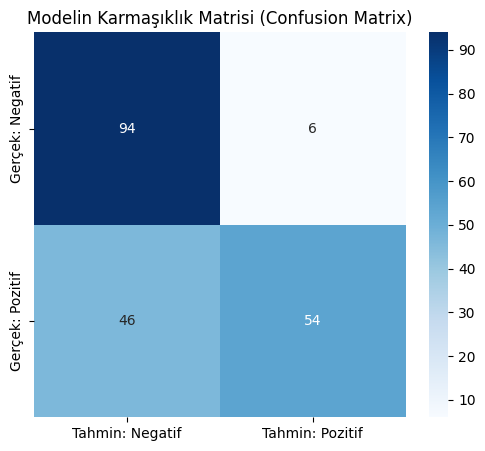

In [23]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Karmaşıklık Matrisini Hesapla
cm = confusion_matrix(gercek_degerler, tahminler)

# Görselleştirme (Isı Haritası)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Tahmin: Negatif', 'Tahmin: Pozitif'],
            yticklabels=['Gerçek: Negatif', 'Gerçek: Pozitif'])
plt.title('Modelin Karmaşıklık Matrisi (Confusion Matrix)')
plt.show()

#Ek iyileştirme 1 - Threshold


In [24]:
# Model çok karamsar olduğu için, Negatif kararlarını zorlaştırıyoruz
def esikli_tahmin(etiket, skor, esik_degeri=0.85):
    # Eğer model negatif diyorsa ama güveni %85'in altındaysa, aslında olumludur diyoruz
    if etiket == 'negative' and skor < esik_degeri:
        return 1 # Pozitif yap
    elif etiket == 'negative':
        return 0 # Gerçekten eminsin, Negatif kalsın
    else:
        return 1 # Zaten pozitif demişti

# Yeni kuralı veri setimize uyguluyoruz
test_df['yeni_tahmin'] = test_df.apply(lambda x: esikli_tahmin(x['model_tahmini_metin'], x['guven_skoru']), axis=1)

# Yeni Metrikleri Hesaplayalım
yeni_accuracy = accuracy_score(test_df['sentiment'], test_df['yeni_tahmin'])
print(f"--- EŞİK DEĞERİ OPTİMİZASYONU SONRASI ---")
print(f"Eski Doğruluk Oranı: %74.00")
print(f"Yeni Doğruluk Oranı: %{yeni_accuracy * 100:.2f}\n")

print(classification_report(test_df['sentiment'], test_df['yeni_tahmin'], target_names=['Negatif (0)', 'Pozitif (1)']))

--- EŞİK DEĞERİ OPTİMİZASYONU SONRASI ---
Eski Doğruluk Oranı: %74.00
Yeni Doğruluk Oranı: %81.00

              precision    recall  f1-score   support

 Negatif (0)       0.76      0.91      0.83       100
 Pozitif (1)       0.89      0.71      0.79       100

    accuracy                           0.81       200
   macro avg       0.82      0.81      0.81       200
weighted avg       0.82      0.81      0.81       200



#Ek İyileştirme 2 - Fine Tune

# Veriyi Hazırlama ve Tokenization (Sözcükleri Sayılara Çevirme)

In [25]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments
from datasets import Dataset
import numpy as np
from sklearn.metrics import accuracy_score

print("1. Veri setleri hazırlanıyor...")
# Eğitim için 2000 veri seçelim (1000 pozitif, 1000 negatif dengeli seçmek en iyisidir)
df_train_neg = df[df['sentiment'] == 0].sample(1000, random_state=42)
df_train_poz = df[df['sentiment'] == 1].sample(1000, random_state=42)
df_train = pd.concat([df_train_neg, df_train_poz]).sample(frac=1, random_state=42).reset_index(drop=True)

# Pandas DataFrame'leri Hugging Face Dataset formatına çeviriyoruz
train_dataset = Dataset.from_pandas(df_train)
test_dataset = Dataset.from_pandas(test_df) # Daha önce ayırdığımız 200'lük test verisi

print("2. Tokenizer (Kelime Çevirici) yükleniyor...")
# Modeli ve Tokenizer'ı indiriyoruz
model_adi = "savasy/bert-base-turkish-sentiment-cased"
tokenizer = AutoTokenizer.from_pretrained(model_adi)

# Metinleri sayılara çeviren fonksiyon
def tokenize_fonksiyonu(ornekler):
    return tokenizer(ornekler["clean_sentence"], padding="max_length", truncation=True, max_length=128)

# Tokenizer'ı veri setlerimize uyguluyoruz
tokenized_train = train_dataset.map(tokenize_fonksiyonu, batched=True)
tokenized_test = test_dataset.map(tokenize_fonksiyonu, batched=True)

# Hugging Face 'Trainer' arka planda etiket sütununun adının "labels" olmasını bekler
tokenized_train = tokenized_train.rename_column("sentiment", "labels")
tokenized_test = tokenized_test.rename_column("sentiment", "labels")

1. Veri setleri hazırlanıyor...
2. Tokenizer (Kelime Çevirici) yükleniyor...


Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/200 [00:00<?, ? examples/s]

#Modelin Eğitimi (Training)

In [26]:
# Gerekli Kütüphaneleri Tekrar Çağırıyoruz (Hata almamak için)
from transformers import AutoModelForSequenceClassification, Trainer, TrainingArguments
import numpy as np
from sklearn.metrics import accuracy_score

print("3. Model yükleniyor ve eğitim parametreleri ayarlanıyor...")
# Sınıflandırma modelini indiriyoruz (num_labels=2 çünkü Pozitif ve Negatif var)
# 'model_adi' değişkeni önceki hücrede "savasy/bert-base-turkish-sentiment-cased" olarak tanımlanmıştı.
# Eğer o da hata verirse doğrudan string olarak içine yazabiliriz:
model = AutoModelForSequenceClassification.from_pretrained("savasy/bert-base-turkish-sentiment-cased", num_labels=2)

# Eğitim sırasında doğruluğu (Accuracy) hesaplayacak fonksiyon
def metrikleri_hesapla(eval_pred):
    logits, labels = eval_pred
    tahminler = np.argmax(logits, axis=-1)
    return {'accuracy': accuracy_score(labels, tahminler)}

# Eğitim Ayarları
egitim_ayarlari = TrainingArguments(
    output_dir="./sonuclar",
    eval_strategy="epoch",            # Güncel versiyona uyumlu parametre
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    weight_decay=0.01,
    logging_dir='./loglar',
)

# Trainer (Eğitici) Kurulumu
trainer = Trainer(
    model=model,
    args=egitim_ayarlari,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_test,
    compute_metrics=metrikleri_hesapla,
)

print("4. EĞİTİM BAŞLIYOR! Lütfen arkanıza yaslanın, bu işlem birkaç dakika sürebilir...")
trainer.train()

3. Model yükleniyor ve eğitim parametreleri ayarlanıyor...


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] `logging_dir` is deprecated and will be removed in v5.2. Please set `TENSORBOARD_LOGGING_DIR` instead.


4. EĞİTİM BAŞLIYOR! Lütfen arkanıza yaslanın, bu işlem birkaç dakika sürebilir...


Epoch,Training Loss,Validation Loss,Accuracy
1,No log,0.168701,0.945000
2,No log,0.059529,0.980000
3,No log,0.043212,0.985000


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=375, training_loss=0.2197219441731771, metrics={'train_runtime': 171.0774, 'train_samples_per_second': 35.072, 'train_steps_per_second': 2.192, 'total_flos': 394666583040000.0, 'train_loss': 0.2197219441731771, 'epoch': 3.0})

/tmp/ipykernel_2497/1277892711.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  grafik = sns.barplot(data=df_karsilastirma, x='Model Versiyonu', y='Doğruluk Oranı (%)', palette=renkler)


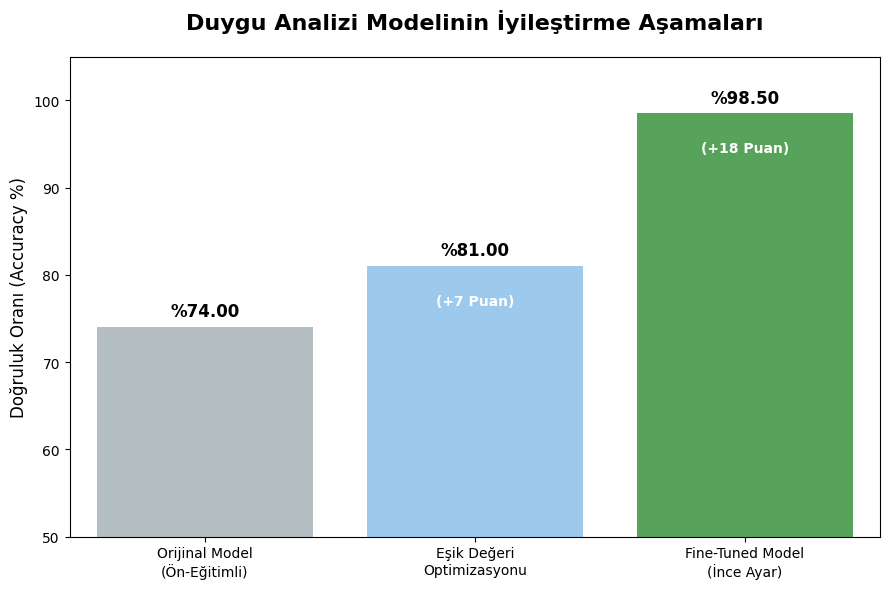

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Elde Ettiğimiz Doğruluk (Accuracy) Değerleri
modeller = ['Orijinal Model\n(Ön-Eğitimli)', 'Eşik Değeri\nOptimizasyonu', 'Fine-Tuned Model\n(İnce Ayar)']
dogruluk_oranlari = [74.00, 81.00, 98.50] # Senin ekran görüntülerinden aldığımız değerler

# Seaborn için DataFrame oluşturuyoruz
df_karsilastirma = pd.DataFrame({
    'Model Versiyonu': modeller,
    'Doğruluk Oranı (%)': dogruluk_oranlari
})

# 2. Görselleştirme (Bar Plot)
plt.figure(figsize=(9, 6))
# Renk paleti ile vurguyu sonuca veriyoruz (griden yeşile)
renkler = ['#b0bec5', '#90caf9', '#4caf50']
grafik = sns.barplot(data=df_karsilastirma, x='Model Versiyonu', y='Doğruluk Oranı (%)', palette=renkler)

# Grafiği Makyajlama
plt.title('Duygu Analizi Modelinin İyileştirme Aşamaları', fontsize=16, fontweight='bold', pad=20)
plt.ylim(50, 105) # Farklar net görünsün diye 50'den başlatıyoruz
plt.ylabel('Doğruluk Oranı (Accuracy %)', fontsize=12)
plt.xlabel('') # Alt kısım zaten net olduğu için etiket koymuyoruz

# Barların (sütunların) üzerine değerleri ve artış oklarını ekleme
for index, p in enumerate(grafik.patches):
    deger = p.get_height()

    # Sayısal değeri yazdır
    grafik.annotate(f"%{deger:.2f}",
                    (p.get_x() + p.get_width() / 2., deger),
                    ha='center', va='bottom',
                    xytext=(0, 5),
                    textcoords='offset points',
                    fontsize=12, fontweight='bold')

    # 2. ve 3. sütunların üzerine "Ne kadar arttı?" bilgisini ekle
    if index > 0:
        artis = deger - dogruluk_oranlari[index-1]
        grafik.annotate(f"(+{artis:.0f} Puan)",
                        (p.get_x() + p.get_width() / 2., deger),
                        ha='center', va='top',
                        xytext=(0, -20),
                        textcoords='offset points',
                        fontsize=10, color='white', fontweight='bold')

plt.tight_layout()
plt.show()

/tmp/ipykernel_2497/172370317.py:16: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(data=test_df, x='sentiment', y='guven_skoru', hue='esik_dogru_bildi_mi',


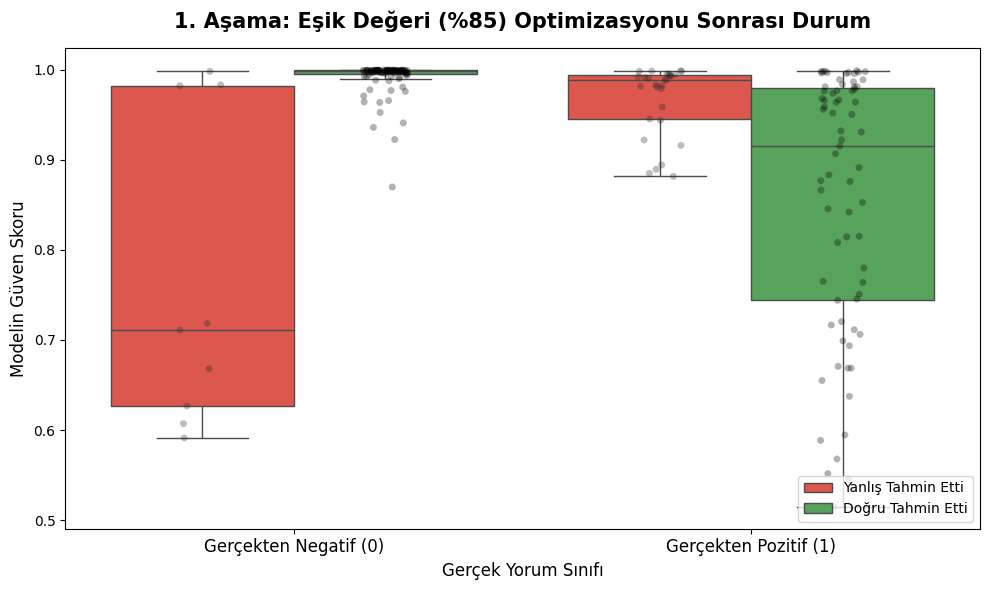

/tmp/ipykernel_2497/172370317.py:48: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(data=test_df, x='sentiment', y='fine_tune_guven_skoru', hue='fine_tune_dogru_bildi_mi',


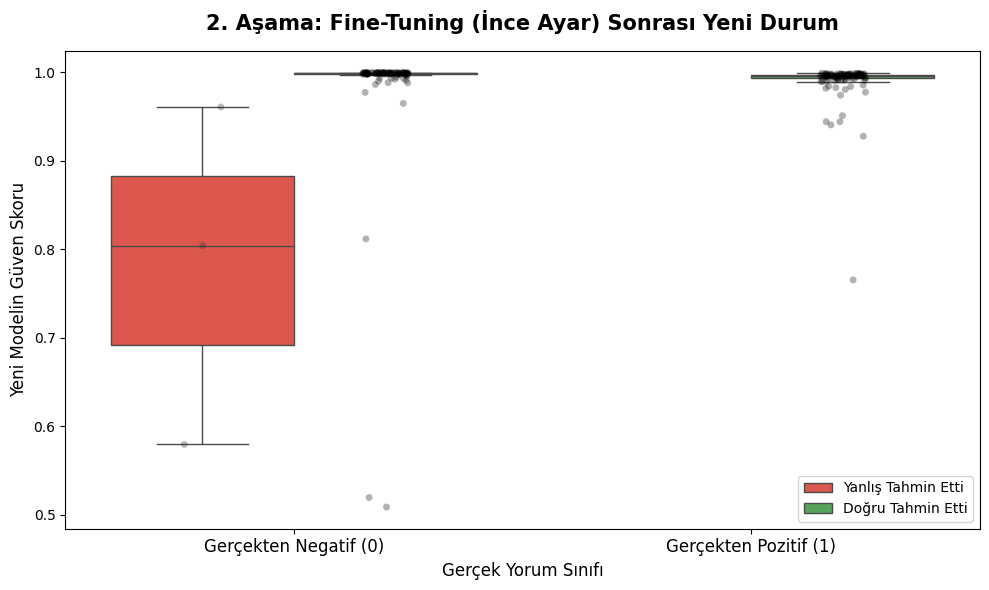

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.special import softmax

# =====================================================================
# 1. GRAFİK: EŞİK DEĞERİ (THRESHOLD) OPTİMİZASYONU SONRASI GÜVEN SKORLARI
# =====================================================================

# Eşik sonrası modelin yeni doğrularını ve yanlışlarını belirliyoruz
test_df['esik_dogru_bildi_mi'] = test_df['sentiment'] == test_df['yeni_tahmin']

plt.figure(figsize=(10, 6))
ax1 = sns.boxplot(data=test_df, x='sentiment', y='guven_skoru', hue='esik_dogru_bildi_mi',
                 palette={True: '#4caf50', False: '#f44336'}, showfliers=False)
sns.stripplot(data=test_df, x='sentiment', y='guven_skoru', hue='esik_dogru_bildi_mi',
              dodge=True, color='black', alpha=0.3, jitter=True, legend=False)

plt.title('1. Aşama: Eşik Değeri (%85) Optimizasyonu Sonrası Durum', fontsize=15, fontweight='bold', pad=15)
plt.xticks(ticks=[0, 1], labels=['Gerçekten Negatif (0)', 'Gerçekten Pozitif (1)'], fontsize=12)
plt.xlabel('Gerçek Yorum Sınıfı', fontsize=12)
plt.ylabel('Modelin Güven Skoru', fontsize=12)

handles, _ = ax1.get_legend_handles_labels()
plt.legend(handles[:2], ['Yanlış Tahmin Etti', 'Doğru Tahmin Etti'], loc='lower right')
plt.tight_layout()
plt.show()

# =====================================================================
# 2. GRAFİK: FINE-TUNE (İNCE AYAR) SONRASI YENİ GÜVEN SKORLARI
# =====================================================================

# Eğittiğimiz modelden (Trainer) test setimiz üzerindeki ham tahminleri (logits) alıyoruz
tahmin_ciktilari = trainer.predict(tokenized_test)
ham_skorlar_logits = tahmin_ciktilari.predictions

# Ham skorları olasılığa (0 ile 1 arasına) çeviriyoruz
yeni_olasiliklar = softmax(ham_skorlar_logits, axis=1)

# En yüksek olasılığa sahip sınıfı ve o olasılık değerini alıyoruz
test_df['fine_tune_tahmin'] = np.argmax(yeni_olasiliklar, axis=1)
test_df['fine_tune_guven_skoru'] = np.max(yeni_olasiliklar, axis=1)
test_df['fine_tune_dogru_bildi_mi'] = test_df['sentiment'] == test_df['fine_tune_tahmin']

plt.figure(figsize=(10, 6))
ax2 = sns.boxplot(data=test_df, x='sentiment', y='fine_tune_guven_skoru', hue='fine_tune_dogru_bildi_mi',
                 palette={True: '#4caf50', False: '#f44336'}, showfliers=False)
sns.stripplot(data=test_df, x='sentiment', y='fine_tune_guven_skoru', hue='fine_tune_dogru_bildi_mi',
              dodge=True, color='black', alpha=0.3, jitter=True, legend=False)

plt.title('2. Aşama: Fine-Tuning (İnce Ayar) Sonrası Yeni Durum', fontsize=15, fontweight='bold', pad=15)
plt.xticks(ticks=[0, 1], labels=['Gerçekten Negatif (0)', 'Gerçekten Pozitif (1)'], fontsize=12)
plt.xlabel('Gerçek Yorum Sınıfı', fontsize=12)
plt.ylabel('Yeni Modelin Güven Skoru', fontsize=12)

handles, _ = ax2.get_legend_handles_labels()
# Eğer model hiç hata yapmadıysa (kırmızı kutu yoksa) lejantı ona göre ayarlıyoruz
if len(handles) > 1:
    plt.legend(handles[:2], ['Yanlış Tahmin Etti', 'Doğru Tahmin Etti'], loc='lower right')
else:
    plt.legend(handles, ['Doğru Tahmin Etti'], loc='lower right')

plt.tight_layout()
plt.show()